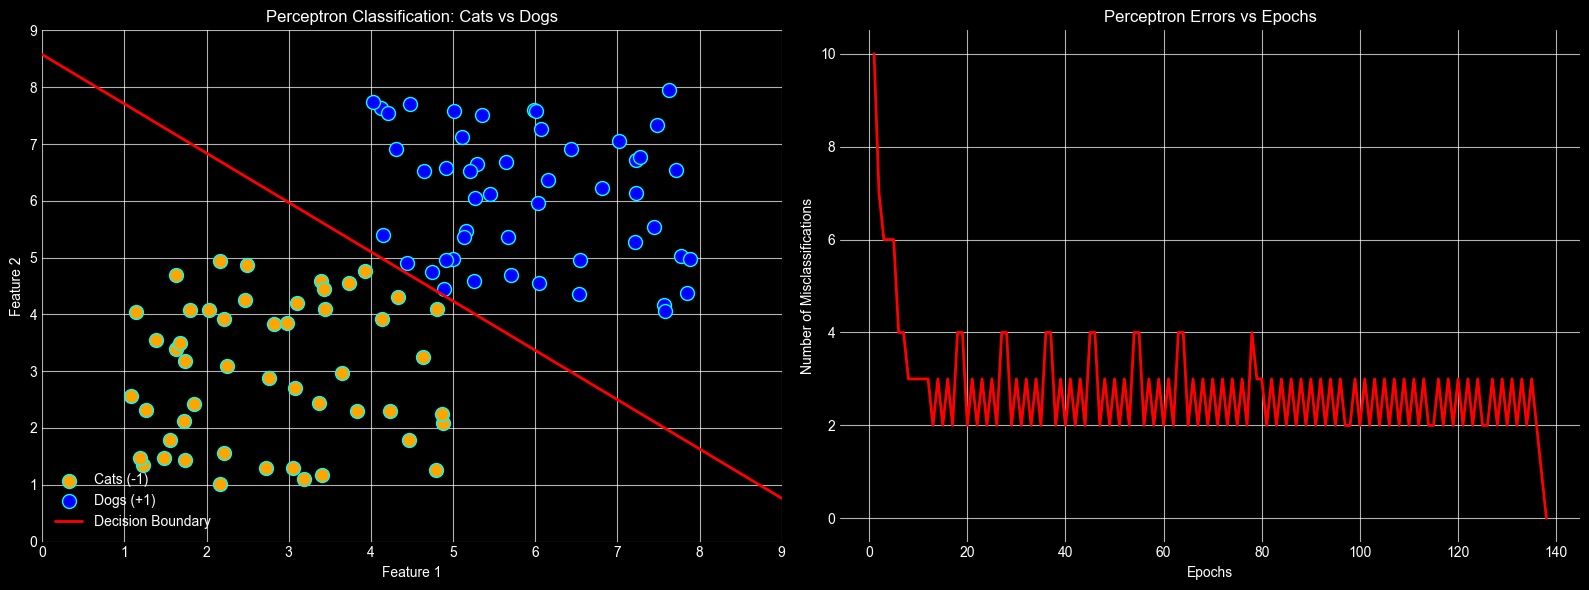

Final Weights: w1=0.1185, w2=0.1365, Bias=-1.1703
Training completed in 138 epochs with 0 misclassifications in the last epoch.


In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('dark_background')

# ==========================================
# 1. Generate Dataset (Cats vs Dogs)
# ==========================================

np.random.seed(42)

n_samples = 50

# Generate Cats Data
cats_x1 = np.random.uniform(1, 5, n_samples)
cats_x2 = np.random.uniform(1, 5, n_samples)

cats = np.column_stack([cats_x1, cats_x2])
cats_labels = -np.ones(n_samples)

# Generate Dogs Data
dogs_x1 = np.random.uniform(4, 8, n_samples)
dogs_x2 = np.random.uniform(4, 8, n_samples)

dogs = np.column_stack([dogs_x1, dogs_x2])
dogs_labels = np.ones(n_samples)

# Combine Dataset
x = np.vstack([cats, dogs])
y = np.concatenate([cats_labels, dogs_labels])


# ==========================================
# 2. Initialize Perceptron Parameters
# ==========================================

np.random.seed(2)

w1 = np.random.rand()
w2 = np.random.rand()
b = np.random.rand()

eta = 0.01
epochs = 1000

errors = np.zeros(epochs)


# ==========================================
# 3. Train Perceptron Model
# ==========================================

for i in range(epochs):

    error_count = 0

    for j in range(len(x)):

        # Calculate Weighted Sum
        z = (w1 * x[j, 0]) + (w2 * x[j, 1]) + b

        # Activation Function (Step Function)
        yhat = 1 if z >= 0 else -1

        # Update Weights if Prediction is Wrong
        if yhat != y[j]:

            w1 += eta * (y[j] - yhat) * x[j, 0]

            w2 += eta * (y[j] - yhat) * x[j, 1]

            b += eta * (y[j] - yhat)

            error_count += 1

    # Store Errors for Each Epoch
    errors[i] = error_count

    # Stop Training if No Errors
    if error_count == 0:
        break


# ==========================================
# 4. Calculate Decision Boundary
# ==========================================

x1_vals = np.linspace(0, 9, 100)

if w2 != 0:
    x2_vals = -(w1 * x1_vals + b) / w2


# ==========================================
# 5. Visualization
# ==========================================

plt.figure(figsize=(16, 6), dpi=100)

# -------- First Plot: Classification --------

plt.subplot(1, 2, 1)

plt.scatter(
    cats[:, 0],
    cats[:, 1],
    c='orange',
    s=100,
    label='Cats (-1)',
    edgecolors='cyan'
)

plt.scatter(
    dogs[:, 0],
    dogs[:, 1],
    c='blue',
    s=100,
    label='Dogs (+1)',
    edgecolors='cyan'
)

if w2 != 0:
    plt.plot(
        x1_vals,
        x2_vals,
        'r-',
        linewidth=2,
        label='Decision Boundary'
    )

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.title('Perceptron Classification: Cats vs Dogs')

plt.legend()
plt.grid(True, alpha=0.7)

plt.xlim(0, 9)
plt.ylim(0, 9)


# -------- Second Plot: Training Errors --------

plt.subplot(1, 2, 2)

plt.plot(
    range(1, i + 2),
    errors[:i + 1],
    color='red',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Number of Misclassifications')

plt.title('Perceptron Errors vs Epochs')

plt.grid(True, alpha=0.7)


# Display Both Plots
plt.tight_layout()
plt.show()


# ==========================================
# 6. Display Final Results
# ==========================================

print(f"Final Weights: w1={w1:.4f}, w2={w2:.4f}, Bias={b:.4f}")

print(
    f"Training completed in {i + 1} epochs "
    f"with {errors[i]:.0f} misclassifications "
    f"in the last epoch."
)

adaline 



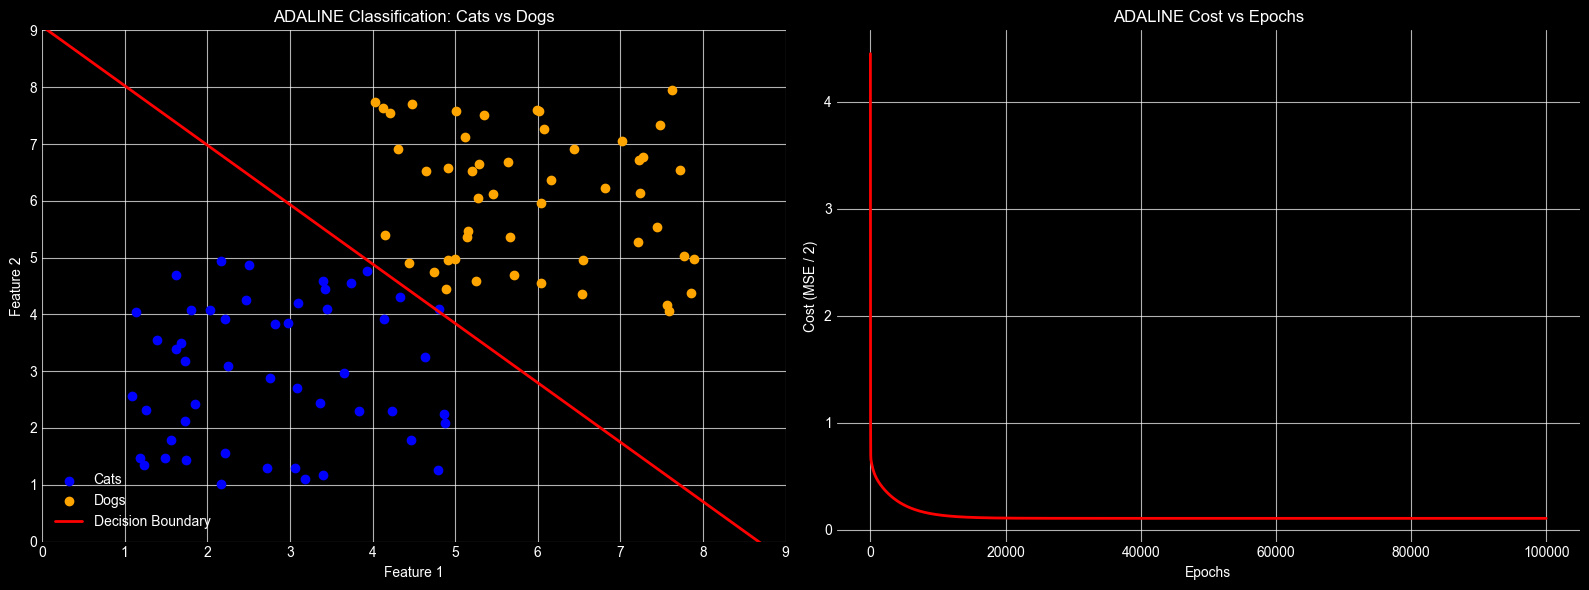

Final Weights: w1=0.2601, w2=0.2487, Bias=-2.2558
Final Cost: 0.104320
Training completed in 100000 epochs with 1 misclassifications.


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. Generate Dataset (Cats vs Dogs)
# ==========================================

np.random.seed(42)

n_samples = 50

# Generate Cats Data
cats_x1 = np.random.uniform(1, 5, n_samples)
cats_x2 = np.random.uniform(1, 5, n_samples)

cats = np.column_stack([cats_x1, cats_x2])
cats_labels = -np.ones(n_samples)

# Generate Dogs Data
dogs_x1 = np.random.uniform(4, 8, n_samples)
dogs_x2 = np.random.uniform(4, 8, n_samples)

dogs = np.column_stack([dogs_x1, dogs_x2])
dogs_labels = np.ones(n_samples)

# Combine Dataset
x = np.vstack([cats, dogs])
y = np.concatenate([cats_labels, dogs_labels])

# Add Bias Column
x_bias = np.column_stack([np.ones(len(x)), x])


# ==========================================
# 2. Initialize ADALINE Parameters
# ==========================================

np.random.seed(2)

w = np.random.rand(3)

eta = 0.001
epochs = 100000

costValue = np.zeros(epochs)
errors = np.zeros(epochs)


# ==========================================
# 3. ADALINE Training (Batch Gradient Descent)
# ==========================================

for i in range(epochs):

    # Linear Output
    z = x_bias @ w

    # Calculate Error
    error = z - y

    # Calculate Gradient
    gradient = (x_bias.T @ error) / len(x)

    # Update Weights
    w = w - eta * gradient

    # Calculate Cost (MSE / 2)
    z_new = x_bias @ w
    error_new = z_new - y

    costValue[i] = 0.5 * np.mean(error_new ** 2)

    # Calculate Misclassifications
    predictions = np.where(z_new >= 0, 1, -1)

    errors[i] = np.sum(predictions != y)

    # Early Stopping
    if costValue[i] < 1e-6:
        break


# ==========================================
# 4. Extract Final Weights
# ==========================================

b = w[0]
w1 = w[1]
w2 = w[2]


# ==========================================
# 5. Plot Results
# ==========================================

plt.figure(figsize=(16, 6), dpi=100)

# ------------------------------------------
# First Plot: Decision Boundary
# ------------------------------------------

plt.subplot(1, 2, 1)

plt.scatter(
    cats[:, 0],
    cats[:, 1],
    color='blue',
    label='Cats'
)

plt.scatter(
    dogs[:, 0],
    dogs[:, 1],
    color='orange',
    label='Dogs'
)

x1_vals = np.linspace(0, 9, 100)

if abs(w2) > 1e-10:
    x2_vals = -(w1 * x1_vals + b) / w2

    plt.plot(
        x1_vals,
        x2_vals,
        color='red',
        linewidth=2,
        label='Decision Boundary'
    )

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')

plt.title('ADALINE Classification: Cats vs Dogs')

plt.legend()
plt.grid(True, alpha=0.7)

plt.xlim(0, 9)
plt.ylim(0, 9)


# ------------------------------------------
# Second Plot: Cost Function
# ------------------------------------------

plt.subplot(1, 2, 2)

plt.plot(
    range(1, i + 2),
    costValue[:i + 1],
    color='red',
    linewidth=2
)

plt.xlabel('Epochs')
plt.ylabel('Cost (MSE / 2)')

plt.title('ADALINE Cost vs Epochs')

plt.grid(True, alpha=0.7)


# ==========================================
# 6. Display Results
# ==========================================

plt.tight_layout()
plt.show()


# ==========================================
# 7. Print Final Results
# ==========================================

print(f"Final Weights: w1={w1:.4f}, w2={w2:.4f}, Bias={b:.4f}")

print(f"Final Cost: {costValue[i]:.6f}")

print(
    f"Training completed in {i + 1} epochs "
    f"with {errors[i]:.0f} misclassifications."
)